#Import lib

In [54]:
!pip install cleverhans

In [55]:
import math
import numpy as np
import tensorflow as tf
import tensorflow_datasets as tfds
from absl import app, flags
from easydict import EasyDict
from tensorflow.keras import Model
from tensorflow.keras.layers import MaxPooling2D, Dropout, Flatten, Dense, BatchNormalization, Conv2D, Input

from cleverhans.tf2.attacks.projected_gradient_descent import projected_gradient_descent
from cleverhans.tf2.attacks.fast_gradient_method import fast_gradient_method

import matplotlib.pyplot as plt


## LOAD CIFAR-10 DATASET

In [56]:
def ld_cifar10():
    """Load training and test data."""

    def convert_types(image, label):
        image = tf.cast(image, tf.float32)
        image /= 127.5
        image -= 1.0
        return image, label

    dataset, info = tfds.load("cifar10", with_info=True, as_supervised=True)

    def augment_mirror(x):
        return tf.image.random_flip_left_right(x)

    def augment_shift(x, w=4):
        y = tf.pad(x, [[w] * 2, [w] * 2, [0] * 2], mode="REFLECT")
        return tf.image.random_crop(y, tf.shape(x))

    cifar10_train, cifar10_test = dataset["train"], dataset["test"]
    # Augmentation helps a lot in CIFAR10
    cifar10_train = cifar10_train.map(
        lambda x, y: (augment_mirror(augment_shift(x)), y)
    )
    cifar10_train = cifar10_train.map(convert_types).shuffle(10000).batch(128)
    cifar10_test = cifar10_test.map(convert_types).batch(1000)

    return EasyDict(train=cifar10_train, test=cifar10_test)

In [57]:
# Variables
nb_epochs=10
adv_perturbation_budget=0.05
pgd_iterations=40
pgd_step_budget=0.01

adv_train=False

# Load training and test data
data = ld_cifar10()
i = Input(shape = (32,32,3))
x = Conv2D(64, (3,3), padding="same", activation="relu")(i)
x = Conv2D(128, (3,3), activation="relu")(x)
x = MaxPooling2D(pool_size=(2,2))(x)
x = Dropout(0.30)(x)
x = Conv2D(64, (3,3), padding="same", activation="relu")(x)
x = Conv2D(128, (3,3), activation="relu")(x)
x = MaxPooling2D(pool_size=(2,2))(x)
x = Dropout(0.30)(x)
x = Conv2D(64, (3,3), padding="same", activation="relu")(x)
x = Conv2D(128, (3,3), activation="relu")(x)
x = MaxPooling2D(pool_size=(2,2))(x)
x = BatchNormalization()(x)
x = Flatten()(x)
x = Dense(10)(x)

model = Model(i, x)
model.summary()

loss_object = tf.losses.SparseCategoricalCrossentropy(from_logits=True)
optimizer = tf.optimizers.Adam(learning_rate=0.001)

# Metrics to track the different accuracies.
train_loss = tf.metrics.Mean(name="train_loss")
train_acc_clean = tf.metrics.SparseCategoricalAccuracy()
test_acc_clean = tf.metrics.SparseCategoricalAccuracy()
test_acc_fgsm = tf.metrics.SparseCategoricalAccuracy()
test_acc_pgd = tf.metrics.SparseCategoricalAccuracy()

@tf.function
def train_step(x, y):
  with tf.GradientTape() as tape:
    predictions = model(x)
    loss = loss_object(y, predictions)
  gradients = tape.gradient(loss, model.trainable_variables)
  optimizer.apply_gradients(zip(gradients, model.trainable_variables))
  train_loss(loss)
  train_acc_clean(y,predictions)

# Train model with adversarial training
for epoch in range(nb_epochs):
  # keras like display of progress
  progress_bar_train = tf.keras.utils.Progbar(50000)
  for (x, y) in data.train:
    if adv_train:
      # Replace clean example with adversarial example for adversarial training
      x = projected_gradient_descent(model, x, adv_perturbation_budget, 0.01, 40, np.inf)
    train_step(x, y)
    progress_bar_train.add(x.shape[0], values=[("epoch",epoch),("Loss (train)", train_loss.result())])



Model: "functional_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer_7 (InputLayer)           │ (None, 32, 32, 3)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_42 (Conv2D)                   │ (None, 32, 32, 64)          │           1,792 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_43 (Conv2D)                   │ (None, 30, 30, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_21 (MaxPooling2D)      │ (None, 15, 15, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_14 (Dropout)                 │ (None, 15, 15, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_44 (Conv2D)                   │ (None, 15, 15, 64)          │          73,792 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_45 (Conv2D)                   │ (None, 13, 13, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_22 (MaxPooling2D)      │ (None, 6, 6, 128)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_15 (Dropout)                 │ (None, 6, 6, 128)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_46 (Conv2D)                   │ (None, 6, 6, 64)            │          73,792 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_47 (Conv2D)                   │ (None, 4, 4, 128)           │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_23 (MaxPooling2D)      │ (None, 2, 2, 128)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_7                │ (None, 2, 2, 128)           │             512 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_7 (Flatten)                  │ (None, 512)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_7 (Dense)                      │ (None, 10)                  │           5,130 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 376,586 (1.44 MB)

 Trainable params: 376,330 (1.44 MB)

 Non-trainable params: 256 (1.00 KB)

50000/50000 ━━━━━━━━━━━━━━━━━━━━ 34s 683us/step - epoch: 0.0000e+00 - Loss (train): 1.8408
50000/50000 ━━━━━━━━━━━━━━━━━━━━ 13s 261us/step - epoch: 1.0000 - Loss (train): 1.4840
50000/50000 ━━━━━━━━━━━━━━━━━━━━ 13s 254us/step - epoch: 2.0000 - Loss (train): 1.3054
50000/50000 ━━━━━━━━━━━━━━━━━━━━ 13s 259us/step - epoch: 3.0000 - Loss (train): 1.1831
50000/50000 ━━━━━━━━━━━━━━━━━━━━ 13s 260us/step - epoch: 4.0000 - Loss (train): 1.0922
50000/50000 ━━━━━━━━━━━━━━━━━━━━ 13s 256us/step - epoch: 5.0000 - Loss (train): 1.0222
50000/50000 ━━━━━━━━━━━━━━━━━━━━ 13s 269us/step - epoch: 6.0000 - Loss (train): 0.9650
50000/50000 ━━━━━━━━━━━━━━━━━━━━ 13s 254us/step - epoch: 7.0000 - Loss (train): 0.9187
50000/50000 ━━━━━━━━━━━━━━━━━━━━ 13s 262us/step - epoch: 8.0000 - Loss (train): 0.8792
50000/50000 ━━━━━━━━━━━━━━━━━━━━ 13s 254us/step - epoch: 9.0000 - Loss (train): 0.8453


 1000/10000 ━━━━━━━━━━━━━━━━━━━━ 37s 4ms/steptest acc on clean examples (%): 83.300
test acc on FGM adversarial examples (%): 21.500
test acc on PGD adversarial examples (%): 10.000
Maximum perturbation:  0.050000012


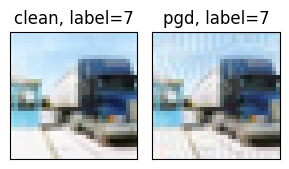

 2000/10000 ━━━━━━━━━━━━━━━━━━━━ 37s 5ms/steptest acc on clean examples (%): 82.350
test acc on FGM adversarial examples (%): 22.500
test acc on PGD adversarial examples (%): 10.600
Maximum perturbation:  0.050000012


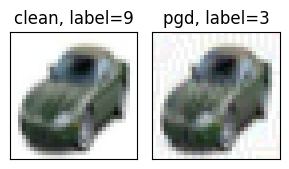

 3000/10000 ━━━━━━━━━━━━━━━━━━━━ 33s 5ms/steptest acc on clean examples (%): 82.600
test acc on FGM adversarial examples (%): 22.567
test acc on PGD adversarial examples (%): 10.067
Maximum perturbation:  0.050000012


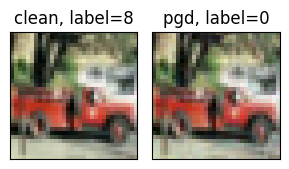

 4000/10000 ━━━━━━━━━━━━━━━━━━━━ 28s 5ms/steptest acc on clean examples (%): 82.325
test acc on FGM adversarial examples (%): 21.900
test acc on PGD adversarial examples (%): 9.675
Maximum perturbation:  0.050000012


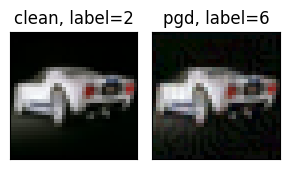

 5000/10000 ━━━━━━━━━━━━━━━━━━━━ 24s 5ms/steptest acc on clean examples (%): 81.960
test acc on FGM adversarial examples (%): 21.600
test acc on PGD adversarial examples (%): 9.960
Maximum perturbation:  0.050000012


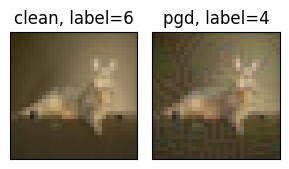

 6000/10000 ━━━━━━━━━━━━━━━━━━━━ 19s 5ms/steptest acc on clean examples (%): 81.767
test acc on FGM adversarial examples (%): 21.933
test acc on PGD adversarial examples (%): 10.017
Maximum perturbation:  0.050000012


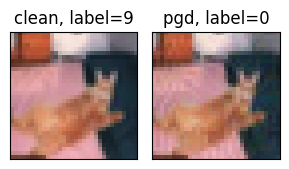

 7000/10000 ━━━━━━━━━━━━━━━━━━━━ 14s 5ms/steptest acc on clean examples (%): 81.629
test acc on FGM adversarial examples (%): 21.786
test acc on PGD adversarial examples (%): 10.000
Maximum perturbation:  0.050000012


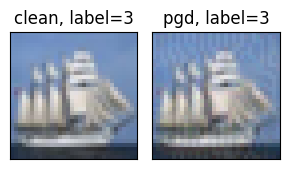

 8000/10000 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step test acc on clean examples (%): 81.575
test acc on FGM adversarial examples (%): 21.800
test acc on PGD adversarial examples (%): 10.125
Maximum perturbation:  0.050000012


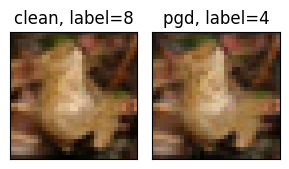

 9000/10000 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/steptest acc on clean examples (%): 81.822
test acc on FGM adversarial examples (%): 21.733
test acc on PGD adversarial examples (%): 10.067
Maximum perturbation:  0.050000012


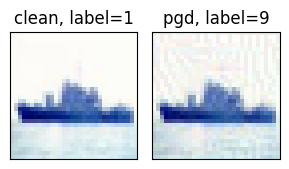

10000/10000 ━━━━━━━━━━━━━━━━━━━━ 50s 5ms/step
test acc on clean examples (%): 81.720
test acc on FGM adversarial examples (%): 21.670
test acc on PGD adversarial examples (%): 10.080
Maximum perturbation:  0.050000012


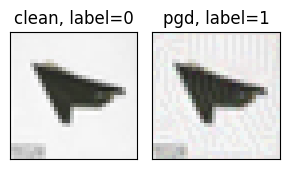

In [58]:
# Evaluate on clean and adversarial data
progress_bar_test = tf.keras.utils.Progbar(10000)
for x, y in data.test:
  #print(np.shape(x))
  y_pred = model(x)
  test_acc_clean(y, y_pred)

  #ATTACKS WITH FGSM
  x_fgm = fast_gradient_method(model, x, adv_perturbation_budget, np.inf)
  y_pred_fgm = model(x_fgm)
  test_acc_fgsm(y, y_pred_fgm)

  #ATTACKS WITH PGD (iterative attack)
  x_pgd = projected_gradient_descent(model, x, adv_perturbation_budget, pgd_step_budget, pgd_iterations, np.inf)
  y_pred_pgd = model(x_pgd)
  test_acc_pgd(y, y_pred_pgd)

  #Print the clean accuracy (no attack) and the adversarial accuracy (i.e., the accuracy computed on the adversarial images)
  #NB: CIFAR-10 has 10 labels, the "random guess level" is accuracy=1/10=0.1
  progress_bar_test.add(x.shape[0])
  print("test acc on clean examples (%): {:.3f}".format(test_acc_clean.result() * 100))
  print("test acc on FGM adversarial examples (%): {:.3f}".format(test_acc_fgsm.result() * 100))
  print("test acc on PGD adversarial examples (%): {:.3f}".format(test_acc_pgd.result() * 100))

  #SHOW THE ATTACK
  rand_sample_id=np.random.randint(np.shape(x)[0])

  #We normalized our images into [0;1]. We make the inverse process to go into [0,255]
  #NB: For the attacked images, the max perturbation is +/-0.05, so the images will be in [-0.05,1.05]
  x_display = tf.cast(127.5*(x[rand_sample_id,:,:,:]+1.0),tf.uint8)
  x_pgd_display = tf.cast(121.4*(x_pgd[rand_sample_id,:,:,:]+1.05),tf.uint8)
  perturbation = x_pgd[rand_sample_id,:,:,:] - x[rand_sample_id,:,:,:]
  print('Maximum perturbation: ',np.amax(perturbation))

  #Display
  fig, axs = plt.subplots(nrows=1, ncols=2, figsize=(3, 2), subplot_kw={'xticks': [], 'yticks': []})
  axs.flat[0].imshow(tf.cast(x_display,tf.uint8))
  axs.flat[0].set_title(str('clean, label=')+str(tf.get_static_value(y[0])))
  axs.flat[1].imshow(tf.cast(x_pgd_display,tf.uint8))
  axs.flat[1].set_title(str('pgd, label=')+str(np.argmax(tf.get_static_value(y_pred_pgd[0]))))
  plt.tight_layout()
  plt.show()